# Customer 360 Data Analysis Project

## Phase 1 — Data Exploration & Profiling

**Objective:** Explore the five datasets, understand their structure and distributions, and identify potential data quality issues and relationship constraints before proceeding to deeper analysis.

**Datasets:** `customers`, `transactions`, `app_usage`, `churn`, and `support_tickets`.

**Scope note:** This phase is exploratory. Potential anomalies are documented without changing or cleaning the original data. Any business meaning or root cause not confirmed by the dataset documentation is treated as unknown.

### 1.1 Import Libraries

Import the Python library required for loading and exploring the datasets.

In [1]:
import pandas as pd

### 1.2 Load the CSV Files

Load the five source CSV files into separate DataFrames.

**Path note:** The code currently uses the original local macOS folder path. If the notebook is opened on another computer or the files are stored in a different folder, update the paths before running the loading cell.

In [2]:
customers = pd.read_csv("/Users/ryshalsbyy/Downloads/archive/customers.csv")
transactions = pd.read_csv("/Users/ryshalsbyy/Downloads/archive/transactions.csv")
app_usage = pd.read_csv("/Users/ryshalsbyy/Downloads/archive/app_usage.csv")
churn = pd.read_csv("/Users/ryshalsbyy/Downloads/archive/churn.csv")
support_tickets = pd.read_csv("/Users/ryshalsbyy/Downloads/archive/support_tickets.csv")


### 1.3 Customer Uniqueness and Dataset Structure — Code

**Objective:**

Check the number of rows, unique customers, and repeated customer IDs in each dataset to understand how the data is structured.

In [3]:
tables = {
    "Customers": customers,
    "Transactions": transactions,
    "App Usage": app_usage,
    "Churn": churn,
    "Support Tickets": support_tickets
}

for name, df in tables.items():
    print(
        name,
        "| Rows:", len(df),
        "| Unique customers:", df["customer_id"].nunique(),
        "| Duplicate customer rows:",
        df["customer_id"].duplicated().sum()
    )

Customers | Rows: 100000 | Unique customers: 100000 | Duplicate customer rows: 0
Transactions | Rows: 500000 | Unique customers: 99285 | Duplicate customer rows: 400715
App Usage | Rows: 100000 | Unique customers: 100000 | Duplicate customer rows: 0
Churn | Rows: 100000 | Unique customers: 100000 | Duplicate customer rows: 0
Support Tickets | Rows: 100000 | Unique customers: 63277 | Duplicate customer rows: 36723


### 1.3 Customer Uniqueness and Dataset Structure

**Objective:**

Examine the number of rows, unique customers, and repeated customer IDs in each dataset to understand the level of detail (grain) and identify potential duplication patterns.

**Key observations:**

- **Customers:** Contains 100,000 rows and 100,000 unique customers, with no repeated customer IDs.
- **Transactions:** Contains 500,000 transactions associated with 99,285 unique customers. Repeated customer IDs are expected because a customer can make multiple transactions.
- **App Usage:** Contains 100,000 rows and 100,000 unique customers, with no repeated customer IDs.
- **Churn:** Contains 100,000 rows and 100,000 unique customers, with no repeated customer IDs.
- **Support Tickets:** Contains 100,000 rows associated with 63,277 unique customers. Repeated customer IDs may occur because a customer can submit multiple support tickets.

**Conclusion:**

The Customers, App Usage, and Churn datasets have one row per customer based on the current results. Transactions and Support Tickets contain repeated customer IDs, which may reflect their different levels of detail rather than data quality issues.

Further checks are needed to confirm the expected structure of each dataset before joining them for analysis.

### 1.4 Exact Duplicate Rows

**Objective:**

Check whether any rows are duplicated across all columns in each dataset.

In [4]:
for name, df in tables.items():
    print(name, "| Exact duplicate rows:", df.duplicated().sum())

Customers | Exact duplicate rows: 0
Transactions | Exact duplicate rows: 0
App Usage | Exact duplicate rows: 0
Churn | Exact duplicate rows: 0
Support Tickets | Exact duplicate rows: 0


### 1.4 Exact Duplicate Rows — Results

Results:

The full duplicate row check returned zero duplicate rows across all five datasets:

### 1.5 Missing Values Analysis

**Objective:**

Check for missing values in each column of the five datasets to identify incomplete data.

In [5]:
for name, df in tables.items():
    print(f"\n{name}")
    print(df.isnull().sum())


Customers
customer_id     0
age             0
gender          0
location        0
income_level    0
signup_date     0
dtype: int64

Transactions
transaction_id      0
customer_id         0
amount              0
category            0
payment_method      0
transaction_date    0
dtype: int64

App Usage
customer_id            0
daily_sessions         0
avg_session_time       0
features_used          0
last_login_days_ago    0
dtype: int64

Churn
customer_id     0
churn           0
churn_reason    0
dtype: int64

Support Tickets
ticket_id             0
customer_id           0
issue_type            0
resolution_time       0
satisfaction_score    0
dtype: int64


### 1.5 Missing Values Analysis — Results

**Results:**

No missing values were found in any column across the five datasets.

**Conclusion:**

All columns are complete based on the missing value check. Further validation is needed to ensure that the values are valid and consistent.

### 1.6 Data Types Inspection

**Objective:**

Inspect the data type of each column to understand how the data is stored and identify columns that may require type conversion before analysis.

In [6]:
for name, df in tables.items():
    print(f"\n{name}")
    print(df.dtypes)


Customers
customer_id      int64
age              int64
gender          object
location        object
income_level    object
signup_date     object
dtype: object

Transactions
transaction_id        int64
customer_id           int64
amount              float64
category             object
payment_method       object
transaction_date     object
dtype: object

App Usage
customer_id              int64
daily_sessions           int64
avg_session_time       float64
features_used            int64
last_login_days_ago      int64
dtype: object

Churn
customer_id      int64
churn            int64
churn_reason    object
dtype: object

Support Tickets
ticket_id              int64
customer_id            int64
issue_type            object
resolution_time        int64
satisfaction_score     int64
dtype: object


### 1.7 Churn Value Inspection

**Objective:**

Inspect the unique values and their frequencies in the `churn` column to understand how customer churn is represented.

In [7]:
print(churn["churn"].value_counts(dropna=False))

churn
0    77673
1    22327
Name: count, dtype: int64


### 1.7 Churn Value Inspection — Results

**Results:**

- Value 0: 77,673 records
- Value 1: 22,327 records
- Total: 100,000 records

**Conclusion:**

The `churn` column contains two distinct values, 0 and 1. The meaning of each value should be confirmed from the dataset documentation before interpreting churn rates.

### 1.8 Churn Reason Inspection

**Objective:**

Explore the values in `churn_reason` and examine how churn reasons are distributed across the dataset.

In [8]:
print(churn["churn_reason"].value_counts(dropna=False))

churn_reason
Price             25182
Bad Experience    24966
Competitor        24943
Low Engagement    24909
Name: count, dtype: int64


### 1.8 Churn Reason Inspection — Results

**Results:**

Four distinct churn reasons were found: Price, Bad Experience, Competitor, and Low Engagement. Each reason appears approximately 25,000 times.

**Observation:**

The total number of records with a churn reason is greater than the number of records where `churn = 1`. This requires further investigation to verify the consistency between churn status and churn reason.

#### Churn Value Validation

**Objective:**
Verify that the `churn` column contains only the expected binary values (0 and 1), and check for any unexpected values.

In [9]:
print(churn["churn"].value_counts(dropna=False).sort_index())

print("\nUnique values:")
print(churn["churn"].unique())

churn
0    77673
1    22327
Name: count, dtype: int64

Unique values:
[0 1]


#### Churn Reason Validation

**Objective:**
Check the unique values and missing entries in the `churn_reason` column to verify its consistency.

In [10]:
print(churn["churn_reason"].value_counts(dropna=False))

print("\nUnique values:")
print(churn["churn_reason"].unique())

churn_reason
Price             25182
Bad Experience    24966
Competitor        24943
Low Engagement    24909
Name: count, dtype: int64

Unique values:
['Price' 'Low Engagement' 'Competitor' 'Bad Experience']


**Findings:**
- The `churn_reason` column contains four unique categories.
- Price has the highest frequency (25,182).
- Low Engagement has the lowest frequency (24,909).
- No missing values were found.
- All four categories have relatively similar frequencies.

**Conclusion:**
Churn reasons are evenly distributed across the dataset. However, reasons are recorded for all customers, including those with a churn value of 0, which requires further clarification regarding the dataset's business logic.

#### Churn Status vs. Churn Reason Consistency

**Objective:**
Examine the relationship between churn status and churn reason to identify whether churn reasons are consistently assigned to customers with different churn statuses.

In [11]:
pd.crosstab(
    churn["churn"],
    churn["churn_reason"]
)

churn_reason,Bad Experience,Competitor,Low Engagement,Price
churn,,,,
0,19347,19322,19434,19570
1,5619,5621,5475,5612


**Findings:**
- All four churn reasons appear under both churn statuses (0 and 1).
- Churn reasons are recorded for customers with both values.
- The distribution of reasons is relatively balanced across both groups.

**Conclusion:**
A consistency issue was identified between `churn` and `churn_reason`. If `churn_reason` represents the actual reason for customer churn, it would be expected to apply only to customers with a churn status of 1. The dataset documentation should be reviewed to clarify the meaning of this column.

### 1.9 Signup Date Range Inspection

**Objective:**

Inspect the earliest and latest customer signup dates to understand the time period covered by the dataset.

In [12]:
print("Earliest signup date:", customers["signup_date"].min())
print("Latest signup date:", customers["signup_date"].max())

Earliest signup date: 2017-01-01
Latest signup date: 2025-01-01


### 1.9 Signup Date Range Inspection — Results

Results:

Earliest signup date: 2017-01-01

Latest signup date: 2025-01-01

Conclusion:

The customer signup dates span from January 1, 2017, to January 1, 2025. Further analysis can explore how customer signups are distributed over time.

### 1.10 Transaction Date Range Inspection

**Objective:**

Inspect the earliest and latest transaction dates to understand the time period covered by customer transactions.

In [13]:
print("Earliest transaction date:", transactions["transaction_date"].min())
print("Latest transaction date:", transactions["transaction_date"].max())

Earliest transaction date: 2018-01-01
Latest transaction date: 2025-01-01


### 1.10 Transaction Date Range Inspection — Results

**Results:**

- Earliest transaction date: 2018-01-01
- Latest transaction date: 2025-01-01

**Conclusion:**

Transaction dates span from January 1, 2018, to January 1, 2025. This period differs from the customer signup date range, which begins in 2017. Further analysis is needed to understand transaction patterns over time.

### 1.11 Date Column Validation

**Objective:**

Check whether the signup and transaction date columns can be converted to datetime format for future time-based analysis.

**Note:** The validation code below uses `errors="coerce"` on temporary converted Series, so it checks convertibility without modifying the original columns.

In [14]:
for name, df, column in [
    ("Customers", customers, "signup_date"),
    ("Transactions", transactions, "transaction_date")
]:
    converted_dates = pd.to_datetime(df[column], errors="coerce")

    print(
        name,
        "| Invalid dates:", converted_dates.isna().sum()
    )

Customers | Invalid dates: 0
Transactions | Invalid dates: 0


### 1.11 Date Column Validation — Results

**Results:**

- Customers (`signup_date`): 0 invalid dates.
- Transactions (`transaction_date`): 0 invalid dates.

**Conclusion:**

All values in both date columns were successfully convertible to datetime format. The next step converts the original columns in place for time-based exploration.

### 1.12 Date Type Conversion

Convert the original signup and transaction date columns to datetime format. This operation updates the DataFrames in place.

In [15]:
customers["signup_date"] = pd.to_datetime(customers["signup_date"])
transactions["transaction_date"] = pd.to_datetime(
    transactions["transaction_date"]
)

### 1.12.1 Verify Date Types

Confirm that both date columns are stored as datetime after conversion.

In [16]:
print("Signup date type:", customers["signup_date"].dtype)
print("Transaction date type:", transactions["transaction_date"].dtype)

Signup date type: datetime64[ns]
Transaction date type: datetime64[ns]


### 1.12 Date Type Conversion — Results

**Results:**

Both `signup_date` and `transaction_date` were successfully converted to `datetime64[ns]`.

**Conclusion:**

The original date columns were converted in place and are now stored in datetime format for time-based exploration.

### 1.13 Categorical Values Inspection

**Objective:**

Explore the unique values in selected categorical columns to understand the categories available for analysis and identify potential inconsistencies.

In [17]:
categorical_columns = {
    "Customers": ["gender", "location", "income_level"],
    "Transactions": ["category", "payment_method"],
    "Churn": ["churn_reason"],
    "Support Tickets": ["issue_type"]
}

for table_name, columns in categorical_columns.items():
    df = tables[table_name]

    for column in columns:
        print(f"\n{table_name} - {column}")
        print(df[column].value_counts())


Customers - gender
gender
Male      50120
Female    49880
Name: count, dtype: int64

Customers - location
location
Mumbai       16859
Bangalore    16669
Chennai      16668
Hyderabad    16634
Kolkata      16603
Delhi        16567
Name: count, dtype: int64

Customers - income_level
income_level
High      33560
Low       33423
Medium    33017
Name: count, dtype: int64

Transactions - category
category
Clothing       100173
Groceries      100050
Health          99998
Electronics     99915
Travel          99864
Name: count, dtype: int64

Transactions - payment_method
payment_method
Net Banking    125407
Wallet         125092
UPI            125040
Card           124461
Name: count, dtype: int64

Churn - churn_reason
churn_reason
Price             25182
Bad Experience    24966
Competitor        24943
Low Engagement    24909
Name: count, dtype: int64

Support Tickets - issue_type
issue_type
Technical    20148
Other        20143
Payment      19935
Refund       19890
Delivery     19884
Name: co

### 1.13 Categorical Values Inspection — Results

**Results:**

- Customer gender, location, and income level categories are represented with relatively balanced counts.
- Transaction categories and payment methods also have similar record counts.
- Four churn reasons and five support ticket issue types were identified.

**Conclusion:**

The selected categorical columns contain clearly defined categories with relatively balanced distributions. Further analysis is needed to understand relationships between these categories and customer behavior.

### 1.14 Numerical Data Inspection

**Objective:**

Review summary statistics for numerical columns to identify unusual values and understand the ranges and distributions of the data.

In [18]:
for name, df in tables.items():
    print(f"\n{name}")
    print(df.describe())


Customers
         customer_id            age                 signup_date
count  100000.000000  100000.000000                      100000
mean    50000.500000      43.500270  2021-01-03 04:16:55.488000
min         1.000000      18.000000         2017-01-01 00:00:00
25%     25000.750000      31.000000         2019-01-01 00:00:00
50%     50000.500000      43.000000         2021-01-05 00:00:00
75%     75000.250000      56.000000         2023-01-04 00:00:00
max    100000.000000      69.000000         2025-01-01 00:00:00
std     28867.657797      14.970933                         NaN

Transactions
       transaction_id    customer_id         amount  \
count   500000.000000  500000.000000  500000.000000   
mean    250000.500000   50026.617794    1998.846150   
min          1.000000       1.000000       0.000000   
25%     125000.750000   25064.000000     575.780000   
50%     250000.500000   50027.000000    1385.920000   
75%     375000.250000   75006.000000    2769.992500   
max     500000

### 1.14 Numerical Data Inspection — Results

**Key observations:**

- Customer ages range from 18 to 69.
- Transaction amounts range from 0 to 24,176.67.
- Daily sessions range from 0 to 13.
- Features used range from 1 to 14.
- Days since last login range from 0 to 59.
- The churn column has a mean of 0.22327.
- Satisfaction scores range from 1 to 5.
- Support ticket resolution times range from 1 to 119.

**Conclusion:**

The summary statistics provide an overview of the numerical data. Further validation is needed to investigate unusual values and confirm the expected ranges and units of measurement.

### 1.15 Zero and Negative Transaction Amount Check

**Objective:**

Count transactions with a zero amount and determine whether any transaction amounts are negative.

In [19]:
print("Zero amount transactions:", (transactions["amount"] == 0).sum())
print("Negative amount transactions:", (transactions["amount"] < 0).sum())

Zero amount transactions: 1
Negative amount transactions: 0


### 1.16 Transaction Amount Distribution

**Objective:**

Examine the distribution of transaction amounts to understand their range and identify unusually high or low values.

In [20]:
print(transactions["amount"].describe(percentiles=[0.01, 0.05, 0.95, 0.99]))

count    500000.000000
mean       1998.846150
std        1998.833231
min           0.000000
1%           20.420000
5%          102.540000
50%        1385.920000
95%        5997.396000
99%        9215.895000
max       24176.670000
Name: amount, dtype: float64


**Results:**

- The dataset contains 500,000 transactions.
- The average transaction amount is 1,998.85, while the median is 1,385.92.
- Transaction amounts range from 0 to 24,176.67.
- The 99th percentile is 9,215.90, meaning 99% of transactions have amounts at or below this value.
- The difference between the mean and median suggests a possible right-skewed distribution, which requires further investigation.

**Note:** The currency and business meaning of the transaction amounts have not yet been confirmed.

### 1.17 99th Percentile Transaction Amount Check

**Objective:**

Count transactions with amounts above the 99th percentile to identify potentially unusually high values for further investigation.

In [21]:
threshold = transactions["amount"].quantile(0.99)

print("99th percentile threshold:", threshold)
print("Transactions above 99th percentile:", (transactions["amount"] > threshold).sum())

99th percentile threshold: 9215.895000000004
Transactions above 99th percentile: 5000


**Results:**

- The 99th percentile threshold is approximately 9,215.90.
- A total of 5,000 transactions (1% of all transactions) have amounts above this threshold.
- These transactions are flagged for further investigation, but they are not automatically considered errors or outliers.



### 1.18 IQR-Based Potential Outlier Check

Calculate the interquartile range (IQR) and upper bound to flag potentially high transaction amounts. These records are candidates for investigation, not confirmed errors.

In [22]:
Q1 = transactions["amount"].quantile(0.25)
Q3 = transactions["amount"].quantile(0.75)

IQR = Q3 - Q1

upper_bound = Q3 + (1.5 * IQR)

outliers = transactions[transactions["amount"] > upper_bound]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Upper bound:", upper_bound)
print("Potential high outliers:", len(outliers))

Q1: 575.78
Q3: 2769.9925
IQR: 2194.2124999999996
Upper bound: 6061.311249999999
Potential high outliers: 24188


**Results — IQR-Based Check**

The code calculates the IQR upper bound and the number of transactions above it. Interpret these records as potential high outliers only; do not classify them as incorrect without business context.

### 1.19 Inspect Potential High Outliers

**Objective:**

Inspect a sample of transactions with amounts above the IQR upper bound to understand their values and related transaction details.

In [23]:
outliers[[
    "transaction_id",
    "customer_id",
    "amount",
    "category",
    "payment_method",
    "transaction_date"
]].head(10)

,transaction_id,customer_id,amount,category,payment_method,transaction_date
35,36,35532,9012.90,Clothing,Net Banking,2022-03-25
51,52,2715,6297.12,Groceries,Net Banking,2024-07-24
100,101,6248,8133.01,Clothing,Wallet,2024-08-31
101,102,51723,7112.84,Groceries,Net Banking,2022-09-29
106,107,73694,11889.42,Travel,UPI,2022-08-10
109,110,20916,7149.15,Clothing,Card,2018-08-18
169,170,47069,6262.05,Groceries,Net Banking,2021-11-16
181,182,17712,6998.60,Health,UPI,2020-11-19
182,183,32511,8213.57,Groceries,Wallet,2023-10-18
214,215,69073,6661.50,Clothing,Net Banking,2019-01-26


**Results:**

- Inspected a sample of 10 transactions classified as potential high outliers using the IQR method.
- The sample contains different transaction categories, payment methods, and dates.
- No clear evidence of incorrect transaction amounts can be established from this sample alone.
- Further investigation is required before deciding whether these values are valid or problematic.

**Decision:** Keep the original data unchanged during this exploratory analysis.

### 1.20 Transaction Amount Summary by Category

Compare transaction counts and summary statistics across categories.

In [24]:
transactions.groupby("category")["amount"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)

,count,mean,median,min,max
category,,,,,
Clothing,100173,1995.71,1379.66,0.02,24103.12
Electronics,99915,2002.95,1398.38,0.10,20339.36
Groceries,100050,1996.69,1381.54,0.00,24176.67
Health,99998,2002.53,1391.96,0.10,22502.71
Travel,99864,1996.36,1377.68,0.01,21440.63


**Results:**

- Transaction counts are relatively balanced across the five categories.
- Average transaction amounts are similar across categories, ranging from approximately 1,995.71 to 2,002.95.
- Median transaction amounts are lower than the means across all categories, suggesting that higher transaction values may influence the averages.
- Groceries has the highest recorded transaction amount at 24,176.67.

**Conclusion:** No substantial differences in average transaction amounts are apparent from this summary alone. Further analysis is needed to understand transaction patterns.

### 1.21 Average Transaction Amount by Category — Visualization

**Objective:**

Create a bar chart to compare average transaction amounts across categories and make differences easier to interpret.

<Axes: title={'center': 'Average Transaction Amount by Category'}, xlabel='Category', ylabel='Average Transaction Amount'>

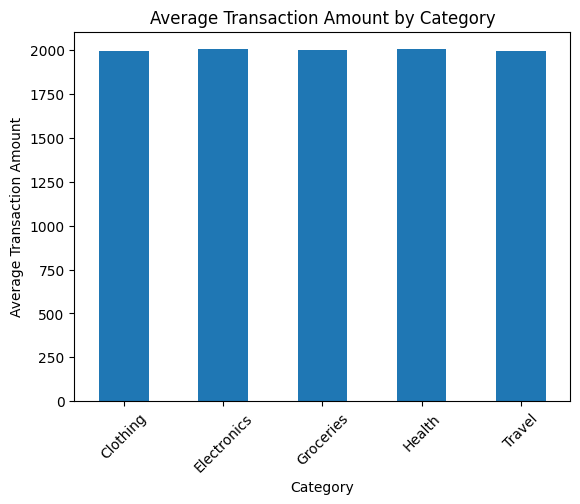

In [25]:
transactions.groupby("category")["amount"].mean().plot(
    kind="bar",
    xlabel="Category",
    ylabel="Average Transaction Amount",
    title="Average Transaction Amount by Category",
    rot=45
)

**Results:**

- The bar chart shows very similar average transaction amounts across all five categories.
- The difference between the highest and lowest category averages is approximately 7.24.
- Category alone does not show a substantial difference in average transaction amount in this dataset.

**Conclusion:** Average transaction amounts are nearly identical across categories. Further analysis is needed to explore other customer and transaction patterns.

### 1.22 Customer App Usage Overview

**Objective:**

Explore customer app usage by examining daily sessions, average session time, features used, and days since the last login.

In [26]:
app_usage[[
    "daily_sessions",
    "avg_session_time",
    "features_used",
    "last_login_days_ago"
]].describe().round(2)

,daily_sessions,avg_session_time,features_used,last_login_days_ago
count,100000.00,100000.00,100000.00,100000.00
mean,3.00,20.47,7.50,29.41
std,1.73,11.24,4.04,17.33
min,0.00,1.00,1.00,0.00
25%,2.00,10.71,4.00,14.00
50%,3.00,20.43,7.00,29.00
75%,4.00,30.18,11.00,44.00
max,13.00,40.00,14.00,59.00


### Results — App Usage Overview

- The dataset contains 100,000 customer records.
- Average daily sessions: 3.00, with a median of 3.
- Average session time: 20.47, with a median of 20.43.
- Average features used: 7.50, with a median of 7.
- Average days since last login: 29.41, with a median of 29.
- No missing values were identified in the initial inspection.

**Note:** The unit of `avg_session_time` has not been confirmed. These statistics provide an initial overview and do not establish customer engagement levels or behavior patterns.

### 1.23 App Usage Value Range Check

**Objective:**

Inspect the minimum and maximum values of app usage columns to identify potentially unusual or invalid values.

In [27]:
usage_columns = [
    "daily_sessions",
    "avg_session_time",
    "features_used",
    "last_login_days_ago"
]

for column in usage_columns:
    print(f"\n{column}")
    print("Negative values:", (app_usage[column] < 0).sum())
    print("Zero values:", (app_usage[column] == 0).sum())


daily_sessions
Negative values: 0
Zero values: 4934

avg_session_time
Negative values: 0
Zero values: 0

features_used
Negative values: 0
Zero values: 0

last_login_days_ago
Negative values: 0
Zero values: 1701


**Results — App Usage Value Range Check**

- No negative values were found across the four app usage columns.
- `daily_sessions`: 4,934 records have zero sessions.
- `avg_session_time`: No zero values were found.
- `features_used`: No zero values were found.
- `last_login_days_ago`: 1,701 records have a value of zero, indicating a login on the current day.

**Conclusion:** No obvious invalid negative values were identified. Zero values in daily sessions and last login days require contextual interpretation and are not automatically considered data quality issues.

### 1.24 Daily Sessions Distribution

**Objective:**

Examine the frequency distribution of daily sessions to understand how customer activity is distributed across different session counts.

In [28]:
print(app_usage["daily_sessions"].value_counts().sort_index())

daily_sessions
0      4934
1     14901
2     22360
3     22520
4     16711
5     10150
6      5090
7      2155
8       800
9       267
10       83
11       22
12        5
13        2
Name: count, dtype: int64


**Results — Daily Sessions Distribution**

- The most frequent value is 3 daily sessions, recorded for 22,520 customers.
- Approximately 61.59% of customers have between 2 and 4 daily sessions.
- Only 1,179 customers (1.18%) have 8 or more daily sessions.
- The distribution is concentrated around 2–4 sessions, with a smaller number of customers having higher session counts.

**Conclusion:** Daily app usage is mainly concentrated around 2–4 sessions per customer, while very high session counts are relatively uncommon.

### 1.25 Average Session Time Distribution

**Objective:**

Examine the distribution of average session time values to understand how session durations vary across customers.

In [29]:
print(app_usage["avg_session_time"].describe(
    percentiles=[0.25, 0.50, 0.75]
))

count    100000.000000
mean         20.465140
std          11.243346
min           1.000000
25%          10.710000
50%          20.430000
75%          30.180000
max          40.000000
Name: avg_session_time, dtype: float64


### 1.26 Features Used Distribution

**Objective:**
Examine how many application features customers use and understand the distribution of feature usage across customers.

In [30]:
print(app_usage["features_used"].value_counts().sort_index())

features_used
1     7133
2     7266
3     7266
4     7043
5     6976
6     7137
7     7219
8     7106
9     7160
10    7156
11    7068
12    7142
13    7190
14    7138
Name: count, dtype: int64


**Findings:**
- The number of features used ranges from 1 to 14.
- Customer counts are relatively evenly distributed across all feature usage levels.
- No single feature usage count dominates the distribution.

**Conclusion:**
Feature usage is relatively balanced across customers, with no clear concentration around a specific number of features.

### 1.27 Last Login Days Distribution

**Objective:**
Examine how many days have passed since each customer's last login to understand the distribution of customer recency.

In [31]:
print(app_usage["last_login_days_ago"].value_counts().sort_index())

last_login_days_ago
0     1701
1     1763
2     1703
3     1684
4     1689
5     1715
6     1621
7     1627
8     1582
9     1574
10    1636
11    1771
12    1692
13    1690
14    1660
15    1675
16    1677
17    1646
18    1742
19    1753
20    1675
21    1617
22    1666
23    1632
24    1733
25    1650
26    1663
27    1679
28    1609
29    1697
30    1677
31    1655
32    1726
33    1649
34    1611
35    1757
36    1630
37    1670
38    1711
39    1592
40    1669
41    1725
42    1605
43    1694
44    1595
45    1658
46    1614
47    1621
48    1576
49    1718
50    1635
51    1699
52    1688
53    1662
54    1626
55    1661
56    1657
57    1681
58    1688
59    1628
Name: count, dtype: int64


**Findings:**
- The number of days since the last login ranges from 0 to 59 days.
- Customer counts are relatively evenly distributed across all values.
- No specific last-login period shows a clear concentration of customers.

**Conclusion:**
Last login recency is relatively evenly distributed across the dataset. Further analysis is needed to understand its relationship with customer churn.

# 1.28 Support Tickets Data Exploration

In this section, we will explore the Support Tickets dataset to understand customer support requests, issue types, resolution times, and customer satisfaction scores.

**Dataset:** `support_tickets`

**Exploration Objectives:**
- Examine support ticket issue types.
- Explore ticket resolution times.
- Analyze customer satisfaction scores.
- Identify unusual values and patterns in the data.
**Objective:**
Examine the frequency of each support ticket issue type to understand the distribution of customer support requests.

### 1.28.1 Issue Type Distribution

**Objective:**
Examine the frequency of each support ticket issue type to understand the distribution of customer support requests.

In [32]:
print(support_tickets["issue_type"].value_counts())

issue_type
Technical    20148
Other        20143
Payment      19935
Refund       19890
Delivery     19884
Name: count, dtype: int64


**Findings:**
- Technical issues have the highest number of tickets (20,148).
- Delivery issues have the lowest number of tickets (19,884).
- Ticket counts are relatively balanced across all five issue types.

**Conclusion:**
Support tickets are evenly distributed across issue types, with no single category dominating the dataset.

### 1.28.2 Resolution Time Distribution

**Objective:**
Examine the distribution of ticket resolution times to understand how long support tickets take to be resolved.

In [33]:
print(support_tickets["resolution_time"].describe())

count    100000.000000
mean         60.068230
std          34.376026
min           1.000000
25%          30.000000
50%          60.000000
75%          90.000000
max         119.000000
Name: resolution_time, dtype: float64


**Findings:**
- The dataset contains 100,000 support tickets.
- Resolution time ranges from 1 to 119.
- The average resolution time is approximately 60.07.
- The median resolution time is 60.
- The first and third quartiles are 30 and 90, respectively.

**Conclusion:**
Resolution times are centered around 60, with the mean and median showing similar values. The measurement unit is not specified in the dataset.

### 1.28.3 Satisfaction Score Distribution

**Objective:**
Examine the frequency of customer satisfaction scores to understand how customers rate their support experience.

In [34]:
print(support_tickets["satisfaction_score"].value_counts().sort_index())

satisfaction_score
1    19897
2    20062
3    19994
4    20111
5    19936
Name: count, dtype: int64


**Findings:**
- Satisfaction scores range from 1 to 5.
- Score 4 has the highest frequency (20,111).
- Score 1 has the lowest frequency (19,897).
- Customer counts are relatively evenly distributed across all satisfaction scores.

**Conclusion:**
Satisfaction scores are evenly distributed, with no clear concentration around high or low ratings. The score interpretation should be confirmed using dataset documentation.

### 1.28.4 Support Tickets — Unusual Values Check

**Objective:**
Check for negative and zero resolution times, and verify that satisfaction scores fall within the expected range of 1 to 5.

In [35]:
print("Negative resolution times:",
      (support_tickets["resolution_time"] < 0).sum())

print("Zero resolution times:",
      (support_tickets["resolution_time"] == 0).sum())

print("Satisfaction scores below 1:",
      (support_tickets["satisfaction_score"] < 1).sum())

print("Satisfaction scores above 5:",
      (support_tickets["satisfaction_score"] > 5).sum())

Negative resolution times: 0
Zero resolution times: 0
Satisfaction scores below 1: 0
Satisfaction scores above 5: 0


**Findings:**
- No negative resolution times were found.
- No zero resolution times were found.
- All satisfaction scores fall within the expected range of 1 to 5.
- No out-of-range satisfaction scores were detected.

**Conclusion:**
The examined numerical values are within their expected ranges, with no unusual values identified by these checks.

# 1.29 Data Relationships & Referential Integrity

In this section, we will examine the relationships between the five datasets using shared customer identifiers.

**Exploration Objectives:**
- Verify customer ID consistency across datasets.
- Identify orphan customer records.
- Check primary key uniqueness in each dataset.
- Examine relationships between customers and related records.

**Key Field:** `customer_id`

**Reference Dataset:** `Customers`

### 1.29.1 Customer ID Referential Integrity

**Objective:**
Verify that customer IDs in all related datasets exist in the Customers table.

This check identifies orphan customer IDs and ensures referential consistency across the datasets.

**Datasets Checked:**
- Transactions
- App Usage
- Churn
- Support Tickets

In [36]:
# Get customer IDs from the Customers dataset
customer_ids = set(customers["customer_id"])

# Define related datasets
related_tables = {
    "Transactions": transactions,
    "App Usage": app_usage,
    "Churn": churn,
    "Support Tickets": support_tickets
}

# Check customer ID integrity across all datasets
integrity_results = []

for table_name, df in related_tables.items():
    related_ids = set(df["customer_id"])
    orphan_ids = related_ids - customer_ids

    integrity_results.append({
        "Dataset": table_name,
        "Unique Customers": len(related_ids),
        "Orphan Customer IDs": len(orphan_ids),
        "Status": "Pass" if len(orphan_ids) == 0 else "Fail"
    })

integrity_df = pd.DataFrame(integrity_results)

print(integrity_df.to_string(index=False))

        Dataset  Unique Customers  Orphan Customer IDs Status
   Transactions             99285                    0   Pass
      App Usage            100000                    0   Pass
          Churn            100000                    0   Pass
Support Tickets             63277                    0   Pass


**Findings:**
- All four datasets passed the customer ID integrity check.
- No orphan customer IDs were found.
- All customer references exist in the Customers dataset.

**Conclusion:**
Customer ID references are consistent across all datasets.

### 1.29.2 Primary Key Uniqueness

**Objective:**
Verify that primary key columns contain unique values across the datasets to identify duplicated identifiers and ensure record-level uniqueness.

In [37]:
# Define primary key columns for each dataset
primary_keys = {
    "Customers": (customers, "customer_id"),
    "Transactions": (transactions, "transaction_id"),
    "App Usage": (app_usage, "customer_id"),
    "Churn": (churn, "customer_id"),
    "Support Tickets": (support_tickets, "ticket_id")
}

# Check primary key uniqueness
key_results = []

for table_name, (df, key_column) in primary_keys.items():
    total_records = len(df)
    unique_keys = df[key_column].nunique()
    duplicate_keys = df[key_column].duplicated().sum()

    key_results.append({
        "Dataset": table_name,
        "Key Column": key_column,
        "Total Records": total_records,
        "Unique Keys": unique_keys,
        "Duplicate Keys": duplicate_keys,
        "Status": "Pass" if duplicate_keys == 0 else "Fail"
    })

key_df = pd.DataFrame(key_results)

print(key_df.to_string(index=False))

        Dataset     Key Column  Total Records  Unique Keys  Duplicate Keys Status
      Customers    customer_id         100000       100000               0   Pass
   Transactions transaction_id         500000       500000               0   Pass
      App Usage    customer_id         100000       100000               0   Pass
          Churn    customer_id         100000       100000               0   Pass
Support Tickets      ticket_id         100000       100000               0   Pass


**Findings:**
- All five datasets passed the primary key uniqueness check.
- No duplicate primary keys were found.

**Conclusion:**
All primary keys are unique across the datasets.

### 1.29.3 Customer Relationship Summary

**Objective:**

Summarize the number of records and unique customers in each dataset to compare their levels of detail.

In [38]:
# Compare customer records across related datasets
relationship_results = []

for table_name, df in tables.items():
    relationship_results.append({
        "Dataset": table_name,
        "Total Records": len(df),
        "Unique Customers": df["customer_id"].nunique()
    })

relationship_df = pd.DataFrame(relationship_results)
print(relationship_df.to_string(index=False))

        Dataset  Total Records  Unique Customers
      Customers         100000            100000
   Transactions         500000             99285
      App Usage         100000            100000
          Churn         100000            100000
Support Tickets         100000             63277


**Findings:**
- App Usage and Churn contain one record for each customer.
- Transactions contain multiple records for some customers.
- Support Tickets contain multiple records for some customers.
- All customer IDs exist in the Customers dataset.

**Conclusion:**
The datasets have consistent customer ID relationships, with different record structures depending on the business activity.

### 1.30.1 Transaction Dates vs. Customer Signup Dates

**Objective:**
Check whether any transaction occurred before the customer's signup date to identify potential chronological inconsistencies.

In [39]:
# Map each customer's signup date to their transactions
signup_dates = customers.set_index("customer_id")["signup_date"]

transaction_signup_dates = transactions["customer_id"].map(signup_dates)

# Identify transactions before signup dates
before_signup = transactions["transaction_date"] < transaction_signup_dates

print("Transactions before signup:", before_signup.sum())
print("Percentage:", round(before_signup.mean() * 100, 2), "%")

Transactions before signup: 218693
Percentage: 43.74 %


**Findings:**
- 218,693 transactions occurred before the recorded customer signup dates.
- These transactions represent 43.74% of all transactions.

**Conclusion:**
A potential chronological inconsistency was identified between transaction dates and customer signup dates. Further investigation is required to understand its cause.

### 1.30.2 Sample of Transactions Before Signup

**Objective:**
Inspect sample records where transaction dates precede customer signup dates to understand the nature of the chronological inconsistency.

In [40]:
# Display a sample of transactions before signup
sample_issues = transactions.loc[
    before_signup,
    ["customer_id", "transaction_date"]
].copy()

sample_issues["signup_date"] = sample_issues["customer_id"].map(signup_dates)

sample_issues["days_before_signup"] = (
    sample_issues["signup_date"] - sample_issues["transaction_date"]
).dt.days

sample_issues.head(10)

,customer_id,transaction_date,signup_date,days_before_signup
0,81736,2018-06-28,2019-10-31,490
1,45064,2018-12-01,2021-05-31,912
2,55912,2021-03-30,2024-10-27,1307
4,47119,2020-11-19,2024-03-27,1224
5,17563,2020-07-31,2021-04-08,251
6,42966,2021-05-19,2023-07-23,795
10,2071,2021-11-28,2024-02-17,811
12,78799,2020-09-11,2022-01-26,502
13,14456,2019-02-08,2019-08-02,175
14,28062,2021-11-28,2022-10-14,320


### 1.30.3 Distribution of Date Differences

**Objective:**
Examine the distribution of days between transaction dates and signup dates for records where transactions occurred before signup.

In [41]:
# Calculate date differences for all affected transactions
date_differences = (
    transaction_signup_dates[before_signup]
    - transactions.loc[before_signup, "transaction_date"]
).dt.days

print(date_differences.describe())

count    218693.000000
mean        853.828742
std         602.766031
min           1.000000
25%         344.000000
50%         751.000000
75%        1280.000000
max        2556.000000
dtype: float64


**Findings:**
- 218,693 transactions occurred before the recorded signup dates.
- The average date difference was approximately 854 days.
- The median difference was 751 days.
- The differences ranged from 1 to 2,556 days.

**Conclusion:**
The date inconsistency affects a substantial portion of the transactions, with significant time differences. The underlying cause remains unconfirmed and requires further investigation.

### 1.30.4 Yearly Distribution of Affected Transactions

**Objective:**
Examine the yearly distribution of transactions that occurred before the recorded customer signup dates.

In [42]:
# Extract transaction year for affected records
affected_transactions = transactions.loc[before_signup].copy()

affected_transactions["transaction_year"] = (
    affected_transactions["transaction_date"].dt.year
)

# Count affected transactions by year
yearly_issues = (
    affected_transactions["transaction_year"]
    .value_counts()
    .sort_index()
)

print(yearly_issues)

transaction_year
2018    57745
2019    49074
2020    40509
2021    31357
2022    22018
2023    13531
2024     4459
Name: count, dtype: int64


**Findings:**
- Affected transactions were recorded between 2018 and 2024.
- The highest number of affected transactions occurred in 2018.
- The number of affected transactions decreased progressively over the years.
- No affected transactions were recorded in 2025.

**Conclusion:**
The chronological inconsistency follows a decreasing yearly pattern. Its underlying cause remains unknown.

### 1.30.5 Customer Signup Distribution by Year

**Objective:**
Examine the yearly distribution of customer signup dates to compare it with the distribution of affected transactions.

In [43]:
# Extract signup year
customers["signup_year"] = customers["signup_date"].dt.year

# Count customers by signup year
signup_yearly = customers["signup_year"].value_counts().sort_index()

print(signup_yearly)

signup_year
2017    12397
2018    12579
2019    12360
2020    12527
2021    12515
2022    12504
2023    12498
2024    12593
2025       27
Name: count, dtype: int64


**Findings:**
- Customer signups are distributed relatively evenly between 2017 and 2024.
- Only 27 customers have signup dates in 2025.
- The signup distribution differs from the yearly pattern of affected transactions.

**Conclusion:**
The signup date distribution does not explain the chronological inconsistency. Further investigation would require clarification of the dataset's date definitions.

### 1.31.1 Text Whitespace Consistency Check

**Objective:**
Check categorical text columns for leading or trailing whitespace that may cause inconsistent category values.

In [44]:
# Check for leading or trailing spaces in text columns
for table_name, df in tables.items():
    text_columns = df.select_dtypes(include="object").columns

    for column in text_columns:
        spaces = df[column].str.strip().ne(df[column]).sum()

        if spaces > 0:
            print(f"{table_name} - {column}: {spaces} values")

**Findings (documented in the notebook):**
- The recorded finding states that no leading or trailing whitespace was found in categorical text columns.

**Verification note:** The preceding code cell has no saved output in the uploaded notebook. Rerun it before final approval to confirm this result.

### 1.31.2 Categorical Letter-Case Consistency

**Objective:**
Check whether categorical columns contain values that differ only in letter casing.

In [45]:
# Check for categories that differ only by letter casing
for table_name, df in tables.items():
    text_columns = df.select_dtypes(include="object").columns

    for column in text_columns:
        normalized = df[column].str.strip().str.lower()
        variants = df.groupby(normalized)[column].nunique()

        inconsistent = variants[variants > 1]

        if not inconsistent.empty:
            print(f"{table_name} - {column}:")
            print(inconsistent)

**Findings (documented in the notebook):**
- The recorded finding states that no categorical values differing only by letter casing were found.

**Verification note:** The preceding code cell has no saved output in the uploaded notebook. Rerun it before final approval to confirm this result.